In [1]:
import pandas as pd
import seaborn as sns

In [2]:
df_small = pd.read_csv('IRIS.csv')
df_small

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,Iris-virginica
146,6.3,2.5,5.0,1.9,Iris-virginica
147,6.5,3.0,5.2,2.0,Iris-virginica
148,6.2,3.4,5.4,2.3,Iris-virginica


In [3]:
df_small.isnull().sum()

sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

In [4]:
x = df_small.drop('species', axis=1)
y = df_small['species']

In [5]:
from sklearn import linear_model as lm
from sklearn.model_selection import train_test_split

log_r = lm.LogisticRegression()

In [6]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

log_r.fit(x_train, y_train)

LogisticRegression()

In [7]:
accuracy = log_r.score(x_test, y_test)
print(f"Model Accuracy: {accuracy * 100:.2f}%")

y_pred = log_r.predict(x_test)

Model Accuracy: 100.00%


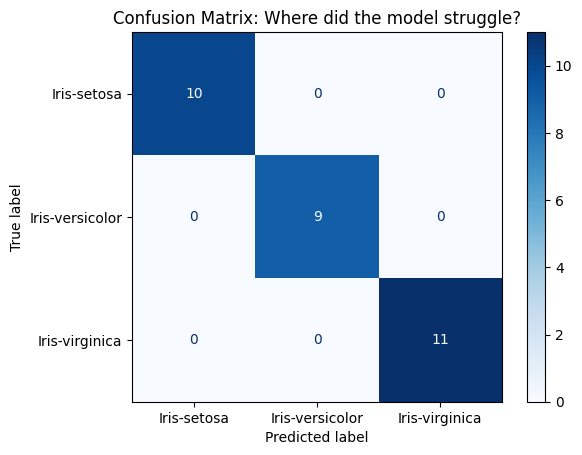

In [8]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Compare predictions to actual values
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=log_r.classes_)

disp.plot(cmap='Blues')
plt.title("Confusion Matrix: Where did the model struggle?")
plt.show()

In [9]:
#Species,Primary Driver,Logic
#Setosa, Petal Length (Negative max), If the petal is short, it's me.
#Versicolor, None (Balanced), If it's not too small or too big, it's me.
#Virginica, Petal Length (Positive max), If the petal is long, it's me.

coef_df = pd.DataFrame(log_r.coef_, columns=x.columns, index=log_r.classes_)
print("Feature Importance (Coefficients):")
print(coef_df)

Feature Importance (Coefficients):
                 sepal_length  sepal_width  petal_length  petal_width
Iris-setosa         -0.396728     0.953397     -2.376680    -1.012149
Iris-versicolor      0.512312    -0.248087     -0.214101    -0.762971
Iris-virginica      -0.115584    -0.705310      2.590781     1.775120


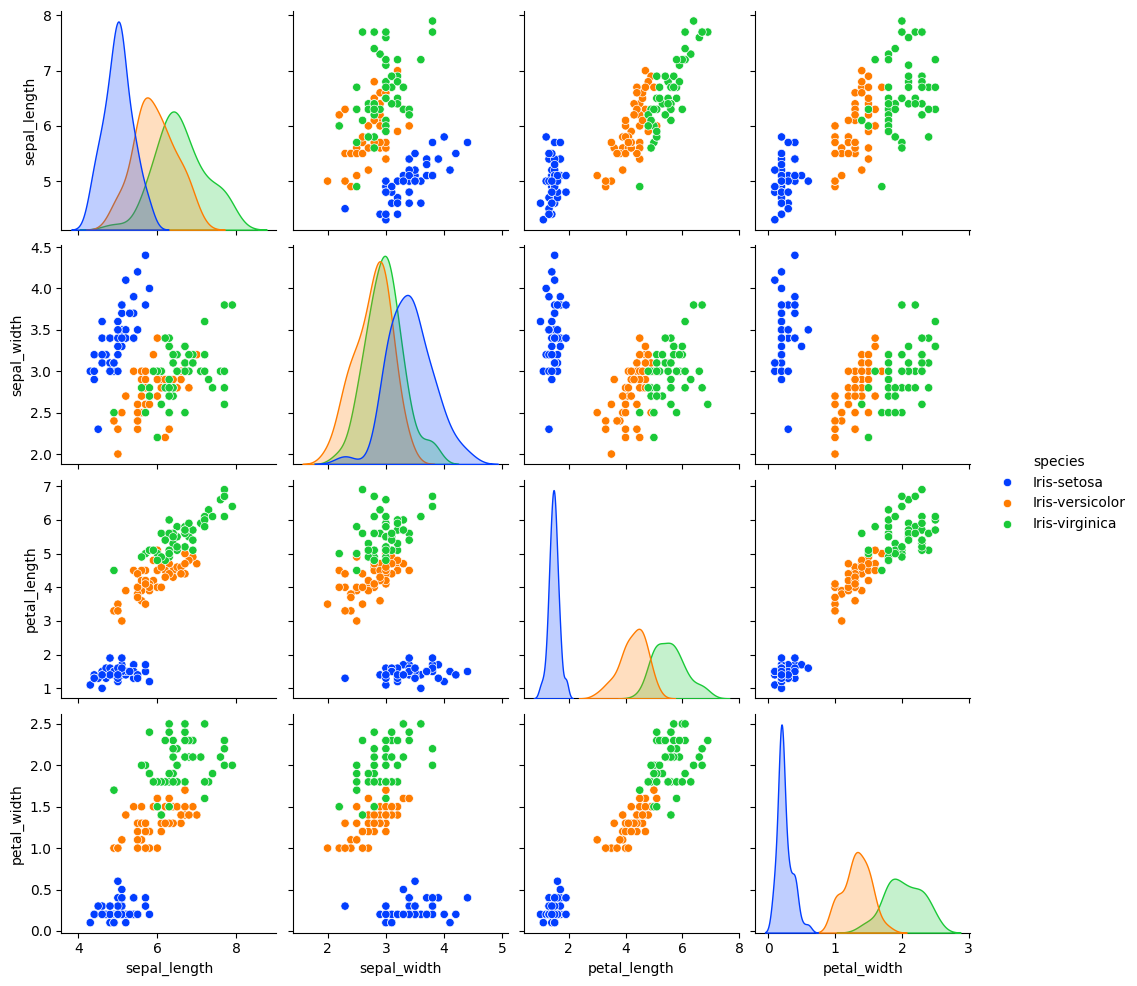

In [10]:
import seaborn as sns
sns.pairplot(df_small, hue='species', palette='bright')
plt.show()

In [11]:
# C=0.1 (stronger penalty) C=100 (weaker penalty)
log_l1 = lm.LogisticRegression(penalty='l1', solver='liblinear', C=10) 
log_l1.fit(x_train, y_train)

l1_coefs = pd.DataFrame(log_l1.coef_, columns=x.columns, index=log_l1.classes_)
l1_coefs

,sepal_length,sepal_width,petal_length,petal_width
Iris-setosa,0.000000,3.924922,-4.390187,0.000000
Iris-versicolor,0.112910,-2.736528,0.900617,-2.089127
Iris-virginica,-2.206848,-4.899717,5.077865,8.598284


In [12]:
print(f"L1 Model Accuracy: {log_l1.score(x_test, y_test) * 100:.2f}%")

L1 Model Accuracy: 100.00%


In [13]:
import pandas as pd

df_med = pd.read_csv('framingham.csv')
df_med

,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4233,1,50,1.0,1,1.0,0.0,0,1,0,313.0,179.0,92.0,25.97,66.0,86.0,1
4234,1,51,3.0,1,43.0,0.0,0,0,0,207.0,126.5,80.0,19.71,65.0,68.0,0
4235,0,48,2.0,1,20.0,NaN,0,0,0,248.0,131.0,72.0,22.00,84.0,86.0,0
4236,0,44,1.0,1,15.0,0.0,0,0,0,210.0,126.5,87.0,19.16,86.0,NaN,0


In [17]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd
# VIF needs data without NaN values, so we drop them for this check
x_temp = x.dropna()

vif_data = pd.DataFrame()
vif_data["feature"] = x_temp.columns
vif_data["VIF"] = [variance_inflation_factor(x_temp.values, i) for i in range(len(x_temp.columns))]

print(vif_data.sort_values(by="VIF", ascending=False))

            feature         VIF
10            sysBP  137.602222
11            diaBP  135.835556
12              BMI   45.051949
1               age   40.890138
13        heartRate   38.740708
9           totChol   31.490107
14          glucose   21.048922
3     currentSmoker    4.854980
2         education    4.746139
4        cigsPerDay    4.158175
7      prevalentHyp    2.387052
0              male    2.090240
8          diabetes    1.566689
5            BPMeds    1.132593
6   prevalentStroke    1.025069


In [42]:
df_med = df_med.fillna(df_med.mean())

x = df_med.drop(columns=['diaBP', 'currentSmoker', 'TenYearCHD'], axis=1)
y = df_med['TenYearCHD']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [43]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [72]:
# REQUIRES HIGHER MODEL
#tradeoff 1 - scaring more ppl saying u have heart disease
log_r = lm.LogisticRegression(class_weight='balanced', penalty='l2', solver='lbfgs', C=10, max_iter=1000)

# tradeoff 2 - risking lives by saying u dont have heart disease
#log_r = lm.LogisticRegression(penalty='l2', solver='lbfgs', C=10, max_iter=1000)


log_r.fit(x_train_scaled, y_train)

# 1. Create the DataFrame and Transpose it with .T
coefs = pd.DataFrame(log_r.coef_, columns=x.columns, index=['Coefficient']).T
coefs_sorted = coefs.sort_values(by='Coefficient', ascending=False)
coefs_sorted

,Coefficient
age,0.592839
sysBP,0.293281
cigsPerDay,0.283485
male,0.197710
glucose,0.137428
prevalentHyp,0.104003
prevalentStroke,0.062947
BPMeds,0.060044
totChol,0.044320
diabetes,0.032926


In [73]:
print(f"Model Accuracy: {log_r.score(x_test_scaled, y_test) * 100:.2f}%")

Model Accuracy: 64.62%


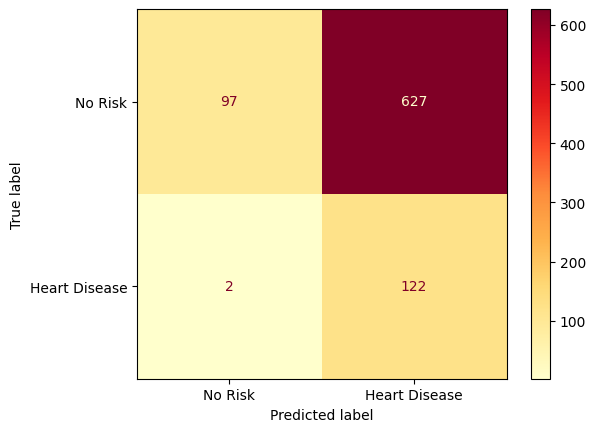

In [74]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Get predictions
y_pred = log_r.predict(x_test_scaled)

# Instead of predict(), we use the probabilities
y_prob = log_r.predict_proba(x_test_scaled)[:, 1]

# Set a lower threshold (e.g., 20% risk is enough to flag them)
y_pred_new = (y_prob >= 0.2).astype(int)

# Plot the new Confusion Matrix
cm_new = confusion_matrix(y_test, y_pred_new)
disp_new = ConfusionMatrixDisplay(confusion_matrix=cm_new, display_labels=["No Risk", "Heart Disease"])
disp_new.plot(cmap='YlOrRd')

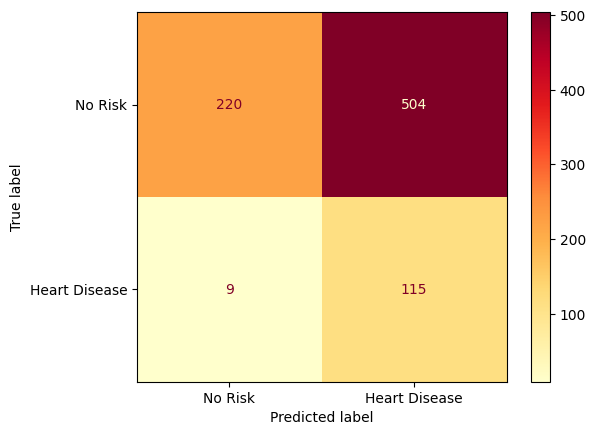

In [75]:
y_pred = log_r.predict(x_test_scaled)

# Instead of predict(), we use the probabilities; setting lower threshold falgs a lot of ppl
y_prob = log_r.predict_proba(x_test_scaled)[:, 1]
y_pred_new = (y_prob >= 0.3).astype(int)

cm_new = confusion_matrix(y_test, y_pred_new)
disp_new = ConfusionMatrixDisplay(confusion_matrix=cm_new, display_labels=["No Risk", "Heart Disease"])
disp_new.plot(cmap='YlOrRd')

In [76]:
from sklearn.model_selection import GridSearchCV

# 1. Define the "Grid" of parameters you want to test
param_grid = {
    'C': [0.001, 0.01, 0.1, 1, 10, 100], 
    'penalty': ['l2'],
    'solver': ['lbfgs']
}

# 2. Initialize the GridSearch
# We set scoring='recall' because we care most about catching the sick people (minimizing that 115)
grid = GridSearchCV(
    lm.LogisticRegression(max_iter=5000, class_weight='balanced'), 
    param_grid, 
    scoring='recall', 
    cv=5 # Cross-validation: splits data 5 times to ensure results aren't a fluke
)

# 3. Fit the grid to your SCALED data
grid.fit(x_train_scaled, y_train)

# 4. See the results
print(f"Best Parameters: {grid.best_params_}")
print(f"Best Recall Score: {grid.best_score_:.2f}")

# 5. Use the "Best" model to predict
best_model = grid.best_estimator_
y_pred_best = best_model.predict(x_test_scaled)

Best Parameters: {'C': 10, 'penalty': 'l2', 'solver': 'lbfgs'}
Best Recall Score: 0.68


In [1]:
import pandas as pd
df_big = pd.read_csv('creditcard.csv')
df_big.head(8)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0
5,2.0,-0.425966,0.960523,1.141109,-0.168252,0.420987,-0.029728,0.476201,0.260314,-0.568671,...,-0.208254,-0.559825,-0.026398,-0.371427,-0.232794,0.105915,0.253844,0.081080,3.67,0
6,4.0,1.229658,0.141004,0.045371,1.202613,0.191881,0.272708,-0.005159,0.081213,0.464960,...,-0.167716,-0.270710,-0.154104,-0.780055,0.750137,-0.257237,0.034507,0.005168,4.99,0
7,7.0,-0.644269,1.417964,1.074380,-0.492199,0.948934,0.428118,1.120631,-3.807864,0.615375,...,1.943465,-1.015455,0.057504,-0.649709,-0.415267,-0.051634,-1.206921,-1.085339,40.80,0


In [5]:
from statsmodels.stats.outliers_influence import variance_inflation_factor as vif

x = df_big.drop('Class', axis=1)
y = df_big['Class']

x_temp = x.dropna()

# VIF Helps in understanding multi-colineireity
vif_data = pd.DataFrame()
vif_data["feature"] = x_temp.columns
vif_data["VIF"] = [vif(x_temp.values, i) for i in range(len(x_temp.columns))]

print(vif_data.sort_values(by="VIF", ascending=False))

   feature        VIF
29  Amount  11.499791
2       V2   3.869377
5       V5   2.753075
7       V7   2.510165
0     Time   2.339084
20     V20   2.233934
1       V1   1.621694
6       V6   1.522122
3       V3   1.255585
23     V23   1.149268
4       V4   1.137944
10     V10   1.115668
21     V21   1.100720
8       V8   1.097151
22     V22   1.082384
19     V19   1.037809
11     V11   1.028861
14     V14   1.026832
9       V9   1.018831
15     V15   1.014135
25     V25   1.013388
12     V12   1.011961
27     V27   1.008979
18     V18   1.006568
17     V17   1.004772
13     V13   1.003434
28     V28   1.001425
24     V24   1.000659
26     V26   1.000487
16     V16   1.000371


In [9]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)

from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x_scaled, y, test_size=0.2, random_state=42)

In [12]:
from sklearn import linear_model as lm

log_r = lm.LogisticRegression(class_weight='balanced', penalty='l2', solver='lbfgs', max_iter=1000)
log_r.fit(x_train, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000)

In [15]:
from sklearn.model_selection import GridSearchCV

# We test a range of C values. Small C = More Regularization (Stiff), Large C = Less Regularization (Flexible)
param_grid = {'C': [0.01, 0.1, 1, 10, 100]}

grid = GridSearchCV(
    lm.LogisticRegression(class_weight='balanced', solver='lbfgs', max_iter=1000),
    param_grid, scoring ='f1', cv=3
)

grid.fit(x_train, y_train)
print(f"Best C found: {grid.best_params_}")

Best C found: {'C': 0.01}


              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56864
           1       0.07      0.92      0.12        98

    accuracy                           0.98     56962
   macro avg       0.53      0.95      0.56     56962
weighted avg       1.00      0.98      0.99     56962



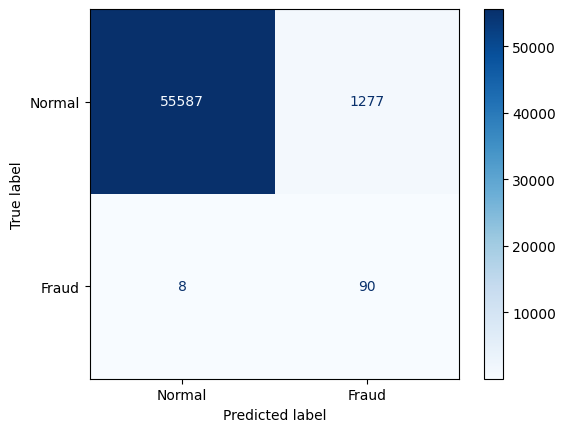

In [16]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

# Use the best model from the grid search
best_model = grid.best_estimator_
y_pred = best_model.predict(x_test)

# Display the Matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Normal", "Fraud"])
disp.plot(cmap='Blues')

# Print the report to see the Precision/Recall numbers
print(classification_report(y_test, y_pred))

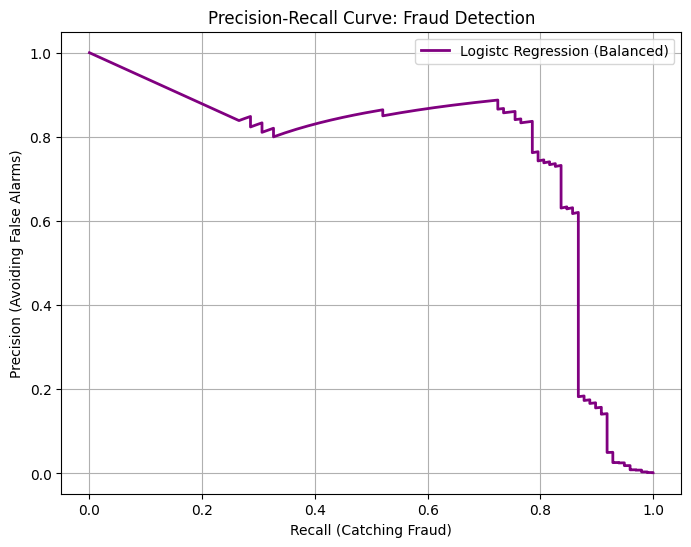

In [17]:
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

# 1. Get the probabilities instead of just 0 or 1
# [:, 1] gives the probability of being "Fraud"
y_scores = best_model.predict_proba(x_test)[:, 1]

# 2. Calculate precision and recall for all possible thresholds
precisions, recalls, thresholds = precision_recall_curve(y_test, y_scores)

# 3. Plot the curve
plt.figure(figsize=(8, 6))
plt.plot(recalls, precisions, color='purple', lw=2, label='Logistc Regression (Balanced)')
plt.xlabel('Recall (Catching Fraud)')
plt.ylabel('Precision (Avoiding False Alarms)')
plt.title('Precision-Recall Curve: Fraud Detection')
plt.grid(True)
plt.legend()
plt.show()

In [18]:
import numpy as np

# Calculate F1 score for each threshold
f1_scores = 2 * (precisions * recalls) / (precisions + recalls)
best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx]

print(f"Best Threshold for F1: {best_threshold:.4f}")
print(f"Best F1 Score: {f1_scores[best_idx]:.4f}")

Best Threshold for F1: 0.9999
Best F1 Score: 0.8105


              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.84      0.79      0.81        98

    accuracy                           1.00     56962
   macro avg       0.92      0.89      0.91     56962
weighted avg       1.00      1.00      1.00     56962



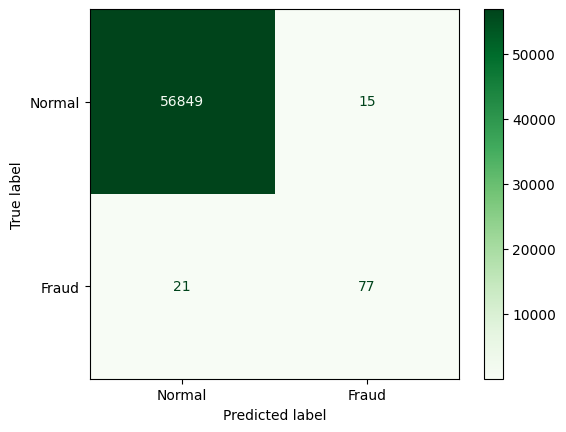

In [20]:
# Apply the best threshold probability score from 0 to 1 (e.g., "I am 70% sure this is fraud").
# The Threshold is the "Rule" we set to make a final decision.
# Default Rule (0.5): If the score is >= 0.5$, call it Fraud.
# Strict Rule (0.9): Only call it Fraud if the score is >= 0.9$.
# Loose Rule (0.1): Call it Fraud if there is even a tiny 10% chance.

y_pred_optimal = (y_scores >= 0.9999).astype(int)

# Look at the new Confusion Matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
new_cm = confusion_matrix(y_test, y_pred_optimal)
disp = ConfusionMatrixDisplay(confusion_matrix=new_cm, display_labels=["Normal", "Fraud"])
disp.plot(cmap='Greens')

from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred_optimal))